In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
import math
from sklearn.metrics import (r2_score,mean_absolute_error,mean_squared_error,make_scorer)
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import (cross_val_score,cross_validate)
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_log_error
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor,AdaBoostRegressor
import category_encoders as ce
from sklearn.model_selection import RandomizedSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import OrdinalEncoder
from catboost import CatBoostRegressor
from sklearn.model_selection import ParameterSampler, KFold

In [3]:
train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')
ss = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv')

/tmp/ipykernel_16/23963074.py:1: DtypeWarning: Columns (38,39) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')


Helper Functions:

In [4]:
def print_diff_between_two_df(frame1,frame2):
    for col in frame1.columns:
        train_unique = set(frame1[col].dropna().astype(str).unique())
        test_unique = set(frame2[col].dropna().astype(str).unique())
    
        diff =  test_unique - train_unique
    
        if len(diff) > 0:
            print(f"\nColumn: {col}")
            print(f"Present in test but not in train: {len(diff)}")
            print(list(diff)[:10])

def split_num_cat_column(frame):
    num_cols = frame.select_dtypes(include=np.number).columns
    cat_cols = frame.select_dtypes(exclude=np.number).columns
    return num_cols,cat_cols

def plot_hist_on_single_column(frame):
    plt.figure(figsize=(4,3))
    sns.histplot(frame, bins=30, kde=True)
    plt.title("TargetValue")
    plt.show()

def plot_hist(frame, num_cols, n_cols=3):
    n = len(num_cols)
    n_rows = math.ceil(n / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(n_cols*3, n_rows*2.5))

    axes = axes.flatten()

    for i, col in enumerate(num_cols):
        sns.histplot(frame[col], bins=30, kde=True, ax=axes[i])
        axes[i].set_title(col, fontsize=9)
        axes[i].tick_params(labelsize=7)

    # Hide unused plots
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

def filter_missing_columns_by_percentage(frame,missing_criteria=90):
    missing_percentage = frame.isna().mean()*100
    missing_columns = missing_percentage[missing_percentage > missing_criteria].index
    return missing_columns


def print_regression_metrics(pred,y):
    print("R² :", r2_score(y, pred))
    print("MAE:", mean_absolute_error(y, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y, pred)))
    print("RMSLE:", np.sqrt(root_mean_squared_log_error(y, pred)))


In [5]:
rmsle_scorer = make_scorer(
    root_mean_squared_log_error,
    greater_is_better=False
)

def evaluate_model(model, preprocessor, X, y, cv=5):

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model",
            TransformedTargetRegressor(
                regressor=model,
                func=np.log1p,
                inverse_func=np.expm1
            )
        )
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring={
            "R2": "r2",
            "RMSE": "neg_root_mean_squared_error",
            "RMSLE": rmsle_scorer
        },
        n_jobs=-1
    )

    return {
        "Model": model.__class__.__name__,
        "R²": scores["test_R2"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "RMSLE": -scores["test_RMSLE"].mean(),
        "Pipeline": pipeline
            }

def create_pipeline(model, preprocessor):

    pipeline = Pipeline([
        ("preprocessor", preprocessor),

        ("model",
            TransformedTargetRegressor(
                regressor=model,
                func=np.log1p,
                inverse_func=np.expm1
            )
        )
    ])

    return pipeline


def evaluate_catboost(model, X, y, cat_cols, cv=5):

    kf = KFold(
        n_splits=cv,
        shuffle=True,
        random_state=42
    )

    r2_scores = []
    rmse_scores = []
    rmsle_scores = []

    for train_idx, valid_idx in kf.split(X):

        X_tr = X.iloc[train_idx].copy()
        X_va = X.iloc[valid_idx].copy()

        y_tr = y.iloc[train_idx]
        y_va = y.iloc[valid_idx]

        model.fit(
            X_tr,
            np.log1p(y_tr),
            cat_features=cat_cols.tolist(),
            verbose=False
        )

        pred = np.expm1(model.predict(X_va))

        r2_scores.append(r2_score(y_va, pred))
        rmse_scores.append(np.sqrt(mean_squared_error(y_va, pred)))
        rmsle_scores.append(root_mean_squared_log_error(y_va, pred))

    return {
        "Model": model.__class__.__name__,
        "R²": np.mean(r2_scores),
        "RMSE": np.mean(rmse_scores),
        "RMSLE": np.mean(rmsle_scores),
        "ModelObject": model
    }

In [6]:
train.head()

,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,...,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139309,57000.0,117665,88,ACH138,GTX,1997,4640.0,Low,2005-03-26,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139316,26500.0,1001282,4616,ACH138,GTX,2005,508.0,Low,2009-12-18,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1139317,21000.0,772709,1948,ACH138,GTX,1994,11540.0,High,2005-08-26,...,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN
3,1139322,27000.0,902010,3550,ACH138,GTX,2002,4883.0,High,2006-11-17,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1139333,21500.0,1036259,36014,ACH138,GTX,2009,302.0,Low,2010-08-27,...,Rubber,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN


In [7]:
print(train.shape)
print(test.shape)

(138701, 50)
(15000, 49)


1. Feature Engineering

In [8]:
y_train = train['TargetValue']
x_train = train.drop(['TargetValue'],axis = 1)

x_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 49 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   TransactionID              138701 non-null  int64  
 1   AssetID                    138701 non-null  int64  
 2   ProductConfigID            138701 non-null  int64  
 3   DataOriginCode             138701 non-null  object 
 4   VendorPartnerID            138701 non-null  object 
 5   ManufactureYear            138701 non-null  int64  
 6   OperationalHoursMeter      82058 non-null   float64
 7   UtilizationTier            50475 non-null   object 
 8   TransactionDate            138701 non-null  object 
 9   Spec_FullDescriptor        138701 non-null  object 
 10  Spec_BaseClass             138701 non-null  object 
 11  Spec_SubClass              101716 non-null  object 
 12  Spec_ReleaseSeries         32896 non-null   object 
 13  Spec_VariantModifier       52

In [9]:
print_diff_between_two_df(x_train,test)


Column: TransactionID
Present in test but not in train: 15000
['1467696', '4336080', '2603324', '2238186', '2410648', '2388627', '6264064', '1539167', '2466834', '4323807']

Column: AssetID
Present in test but not in train: 11385
['1284954', '1185326', '1368573', '1290765', '1455272', '528758', '464197', '1000783', '1418349', '1129981']

Column: ProductConfigID
Present in test but not in train: 83
['8639', '22321', '23891', '26092', '25078', '9598', '8586', '22847', '2246', '25021']

Column: OperationalHoursMeter
Present in test but not in train: 536
['13510.0', '8214.0', '11796.0', '14768.0', '8135.0', '13904.0', '18349.0', '10288.0', '24741.0', '12190.0']

Column: TransactionDate
Present in test but not in train: 38
['2002-11-01', '2004-11-20', '2010-01-12', '2009-08-28', '2012-12-10', '2011-05-11', '2010-01-05', '2008-05-25', '1992-03-23', '2006-10-27']

Column: Spec_FullDescriptor
Present in test but not in train: 80
['1187C', '710VHP', '216BII', '313B', 'G60', '330D', '1150D', 'D

In [10]:
x_train.describe()

,TransactionID,AssetID,ProductConfigID,ManufactureYear,OperationalHoursMeter
count,1.387010e+05,1.387010e+05,138701.000000,138701.000000,8.205800e+04
mean,2.186276e+06,1.204814e+06,7286.421922,1891.640853,4.553719e+03
std,1.128497e+06,5.287376e+05,7542.421537,306.992001,2.792204e+04
min,1.139309e+06,8.000000e+00,39.000000,1001.000000,0.000000e+00
25%,1.465754e+06,1.007930e+06,1693.000000,1990.000000,0.000000e+00
50%,1.751884e+06,1.246956e+06,3852.000000,1998.000000,1.620000e+03
75%,2.372139e+06,1.495817e+06,11873.000000,2004.000000,5.001000e+03
max,6.333410e+06,2.478476e+06,37209.000000,2015.000000,1.729600e+06


Split numerical and non numerical columns:

In [11]:
num_cols,cat_cols = split_num_cat_column(x_train)
print(num_cols)
print(cat_cols)

Index(['TransactionID', 'AssetID', 'ProductConfigID', 'ManufactureYear',
       'OperationalHoursMeter'],
      dtype='object')
Index(['DataOriginCode', 'VendorPartnerID', 'UtilizationTier',
       'TransactionDate', 'Spec_FullDescriptor', 'Spec_BaseClass',
       'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier',
       'AssetScaleFactor', 'FunctionalClassification', 'RegionCode',
       'InventoryGroupCategory', 'InventoryGroupDescription', 'col1',
       'CabinType', 'Forks', 'col3', 'col4', 'DrivetrainType', 'col5', 'col6',
       'col7', 'col8', 'col9', 'col10', 'col11', 'col12', 'col13', 'col14',
       'col15', 'col16', 'col18', 'col19', 'col20', 'col21', 'col22', 'col23',
       'col24', 'col25', 'col27', 'col28', 'col29', 'col30'],
      dtype='object')


Plot the current numerical data:

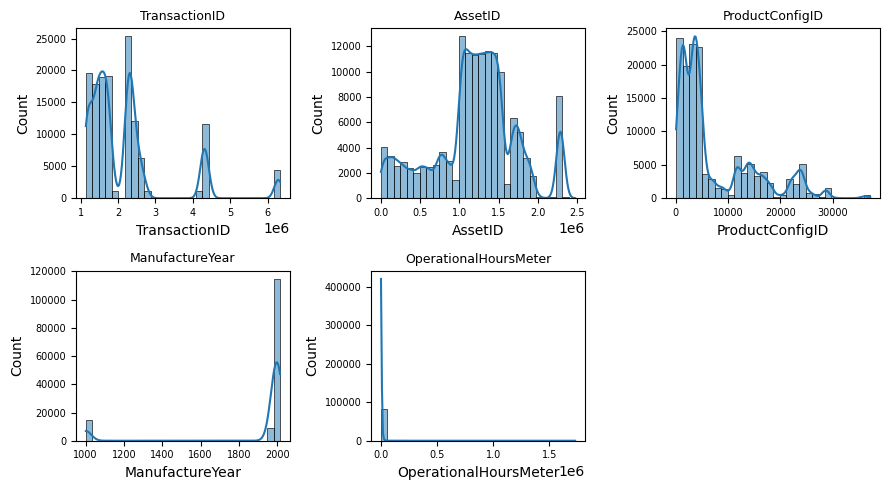

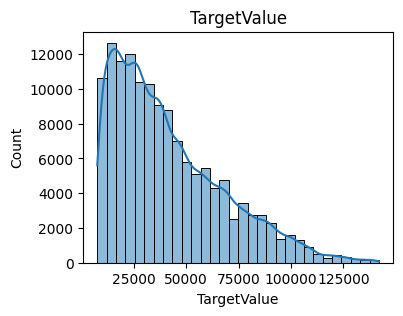

In [12]:
plot_hist(x_train,num_cols)
plot_hist_on_single_column(y_train)

Imputation phase:

In [13]:
x_train.replace("None or Unspecified", np.nan, inplace=True)

missing_columns = filter_missing_columns_by_percentage(x_train,80)

x_train.drop(columns=missing_columns,inplace=True)
test.drop(columns=missing_columns,inplace=True)

x_train["ManufactureYear"].replace(1001, np.nan, inplace=True)
test["ManufactureYear"].replace(1001, np.nan, inplace=True)


x_train["TransactionDate"] = pd.to_datetime(x_train["TransactionDate"])
x_train["TransactionYear"] = x_train["TransactionDate"].dt.year
x_train["TransactionMonth"] = x_train["TransactionDate"].dt.month
x_train["TransactionQuarter"] = x_train["TransactionDate"].dt.quarter
x_train["AssetAge"] = x_train["TransactionYear"] - x_train["ManufactureYear"]
x_train["DescriptorLength"] = x_train["Spec_FullDescriptor"].str.len()
x_train["BaseClassLength"] = x_train["Spec_BaseClass"].str.len()
x_train["HasOperationalHours"] = x_train["OperationalHoursMeter"].notna().astype(int)
x_train["HasVariantModifier"] = x_train["Spec_VariantModifier"].notna().astype(int)
x_train['HoursPerYear'] = x_train['OperationalHoursMeter'] / x_train['AssetAge']
x_train['HoursPerYear'] = x_train['HoursPerYear'].replace(np.inf, np.nan)
x_train["AgeSquared"] = x_train["AssetAge"] ** 2
x_train["MissingCount"] = x_train.isna().sum(axis=1)
x_train["BasePrefix"] = (x_train["Spec_BaseClass"].str.extract(r"([A-Za-z]+)"))
x_train["BaseNumber"] = (x_train["Spec_BaseClass"].str.extract(r"(\d+\.?\d*)").astype(float))
x_train["DescPrefix"] = (x_train["Spec_FullDescriptor"].str.extract(r"^([A-Za-z]+)", expand=False))
x_train["DescNumber"] = (x_train["Spec_FullDescriptor"].str.extract(r"(\d+\.?\d*)", expand=False).astype(float))
x_train["DescSuffix"] = (x_train["Spec_FullDescriptor"].str.extract(r"\d+\.?\d*(.*)",expand=False).str.strip().replace("", np.nan))



test["TransactionDate"] = pd.to_datetime(test["TransactionDate"])
test["TransactionYear"] = test["TransactionDate"].dt.year
test["TransactionMonth"] = test["TransactionDate"].dt.month
test["TransactionQuarter"] = test["TransactionDate"].dt.quarter
test["AssetAge"] = test["TransactionYear"] - test["ManufactureYear"]
test["DescriptorLength"] = test["Spec_FullDescriptor"].str.len()
test["BaseClassLength"] = test["Spec_BaseClass"].str.len()
test["HasOperationalHours"] = test["OperationalHoursMeter"].notna().astype(int)
test["HasVariantModifier"] = test["Spec_VariantModifier"].notna().astype(int)
test['HoursPerYear'] = test['OperationalHoursMeter'] / test['AssetAge']
test['HoursPerYear'] = test['HoursPerYear'].replace(np.inf, np.nan)
test["AgeSquared"] = test["AssetAge"] ** 2
test["MissingCount"] = test.isna().sum(axis=1)
test["BasePrefix"] = (test["Spec_BaseClass"].str.extract(r"([A-Za-z]+)"))
test["BaseNumber"] = (test["Spec_BaseClass"].str.extract(r"(\d+\.?\d*)").astype(float))
test["DescPrefix"] = (test["Spec_FullDescriptor"].str.extract(r"^([A-Za-z]+)", expand=False))
test["DescNumber"] = (test["Spec_FullDescriptor"].str.extract(r"(\d+\.?\d*)", expand=False).astype(float))
test["DescSuffix"] = (test["Spec_FullDescriptor"].str.extract(r"\d+\.?\d*(.*)",expand=False).str.strip().replace("", np.nan))


test_TransactionID = test["TransactionID"].copy()

x_train.drop(columns=['TransactionID','TransactionDate'],inplace=True)
test.drop(columns=['TransactionID','TransactionDate'],inplace=True)


/tmp/ipykernel_16/3645858913.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  x_train["ManufactureYear"].replace(1001, np.nan, inplace=True)
/tmp/ipykernel_16/3645858913.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=Tr

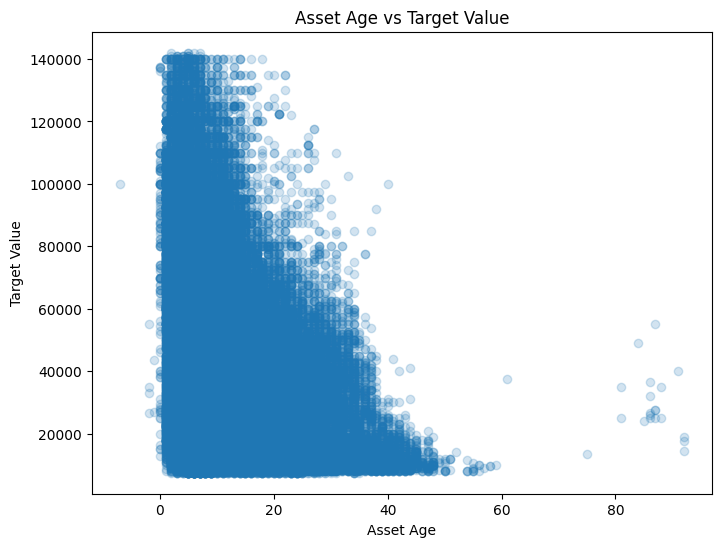

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    x_train["AssetAge"],
    y_train,
    alpha=0.2
)

plt.xlabel("Asset Age")
plt.ylabel("Target Value")
plt.title("Asset Age vs Target Value")

plt.show()

In [15]:
x_train.isna().sum()

AssetID                           0
ProductConfigID                   0
DataOriginCode                    0
VendorPartnerID                   0
ManufactureYear               14719
OperationalHoursMeter         56643
UtilizationTier               88226
Spec_FullDescriptor               0
Spec_BaseClass                    0
Spec_SubClass                 36985
Spec_ReleaseSeries           105805
Spec_VariantModifier          86369
AssetScaleFactor              41210
FunctionalClassification          0
RegionCode                        0
InventoryGroupCategory            0
InventoryGroupDescription         0
col1                         104915
CabinType                         0
col10                         10381
col20                         67685
col25                         67685
TransactionYear                   0
TransactionMonth                  0
TransactionQuarter                0
AssetAge                      14719
DescriptorLength                  0
BaseClassLength             

Impute Missing Columns:

In [16]:
num_cols = x_train.select_dtypes(include=np.number).columns
cat_cols = x_train.select_dtypes(exclude=np.number).columns
print(num_cols)
print(cat_cols)

Index(['AssetID', 'ProductConfigID', 'ManufactureYear',
       'OperationalHoursMeter', 'TransactionYear', 'TransactionMonth',
       'TransactionQuarter', 'AssetAge', 'DescriptorLength', 'BaseClassLength',
       'HasOperationalHours', 'HasVariantModifier', 'HoursPerYear',
       'AgeSquared', 'MissingCount', 'BaseNumber', 'DescNumber'],
      dtype='object')
Index(['DataOriginCode', 'VendorPartnerID', 'UtilizationTier',
       'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass',
       'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor',
       'FunctionalClassification', 'RegionCode', 'InventoryGroupCategory',
       'InventoryGroupDescription', 'col1', 'CabinType', 'col10', 'col20',
       'col25', 'BasePrefix', 'DescPrefix', 'DescSuffix'],
      dtype='object')


Check for High cardinal data

In [17]:
cardinality = x_train[cat_cols].nunique().sort_values(ascending=False)
cardinality

Spec_FullDescriptor          3505
Spec_BaseClass               1249
DescSuffix                    664
Spec_SubClass                 147
Spec_VariantModifier          132
Spec_ReleaseSeries            113
BasePrefix                    111
DescPrefix                    108
FunctionalClassification       65
RegionCode                     53
VendorPartnerID                31
col10                          11
DataOriginCode                  6
AssetScaleFactor                6
InventoryGroupDescription       6
InventoryGroupCategory          6
col1                            4
UtilizationTier                 3
CabinType                       3
col25                           3
col20                           2
dtype: int64

In [18]:
high_card_cols = [
    "DescSuffix",
    "Spec_SubClass",
    "Spec_VariantModifier",
    "Spec_ReleaseSeries",
    "FunctionalClassification",
    "RegionCode",
    "DescPrefix",
    "BasePrefix"
]

onehot_cols = [c for c in cat_cols if c not in high_card_cols]

In [19]:

log_cols = ["OperationalHoursMeter"]
normal_num_cols = [c for c in num_cols if c not in log_cols]
if "UtilizationTier" in onehot_cols:
    onehot_cols.remove("UtilizationTier")

log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, validate=False)),
    ("scaler", StandardScaler())
])

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ))
])

target_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="constant",fill_value="Unknown")),
    ("target",ce.TargetEncoder(smoothing=10))
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OrdinalEncoder(
        categories=[["Unknown", "Low", "Medium", "High"]],
    ))
])

preprocessor = ColumnTransformer([
    ("log_num", log_pipeline, log_cols),
    ("num", num_pipeline, normal_num_cols),
    ("ordinal", ordinal_pipeline, ["UtilizationTier"]),
    ("target", target_pipeline, high_card_cols),
    ("cat", cat_pipeline, onehot_cols)
])

In [20]:
results = []

In [21]:
lr_pipeline = evaluate_model(
    LinearRegression(),
    preprocessor,
    x_train,
    y_train
)
results.append(lr_pipeline)

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found u

In [22]:

ridge_pipeline = evaluate_model(
    Ridge(alpha=1),
    preprocessor,
    x_train,
    y_train
)

results.append(ridge_pipeline)

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found u

In [23]:
dt_pipeline = evaluate_model(
    DecisionTreeRegressor(random_state=42),
    preprocessor,
    x_train,
    y_train
)

results.append(dt_pipeline)

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found u

In [24]:
rf_pipeline = evaluate_model(
    RandomForestRegressor(
                n_estimators=20,
                max_features="sqrt",
                random_state=42,
                n_jobs=1
            ),
    preprocessor,
    x_train,
    y_train
)

results.append(rf_pipeline)

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found u

In [25]:

gb_pipeline = evaluate_model(
    GradientBoostingRegressor(random_state=42),
    preprocessor,
    x_train,
    y_train
)

results.append(gb_pipeline)

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found u

In [26]:
xgb = XGBRegressor(
     n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="reg:squarederror",
    n_jobs=1
)

xgb_pipeline = evaluate_model(
    xgb,
    preprocessor,
    x_train,
    y_train
)

results.append(xgb_pipeline)

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found u

In [27]:
for c in cat_cols:
    x_train[c] = x_train[c].astype(str).fillna("Missing").replace("nan", "Missing")
    test[c] = test[c].astype(str).fillna("Missing").replace("nan", "Missing")

In [28]:
cat = CatBoostRegressor(
loss_function="RMSE",
random_seed=42,
verbose=False
)


cat_results = evaluate_catboost(
    cat,
    x_train,
    y_train,
    cat_cols
)

results.append(cat_results)

In [29]:
importance = cat.get_feature_importance()

feature_importance = (
    pd.DataFrame({
        "Feature": x_train.columns,
        "Importance": importance
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

feature_importance.head(30)

,Feature,Importance
0,FunctionalClassification,14.217330
1,ManufactureYear,13.665937
2,Spec_FullDescriptor,11.001511
3,DescSuffix,9.116440
4,AssetAge,8.514004
5,TransactionYear,8.040863
6,AgeSquared,6.446123
7,CabinType,4.069590
8,AssetScaleFactor,4.050432
9,Spec_SubClass,3.628937


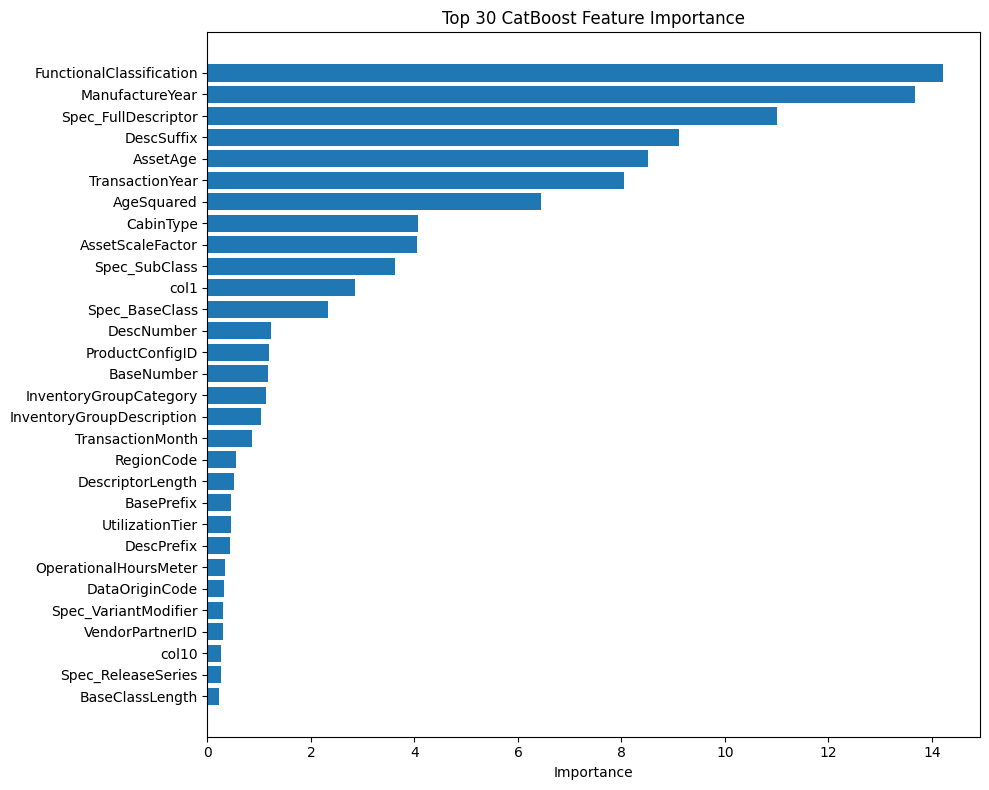

In [30]:
import matplotlib.pyplot as plt

top_n = 30

plt.figure(figsize=(10,8))

plt.barh(
    feature_importance["Feature"][:top_n][::-1],
    feature_importance["Importance"][:top_n][::-1]
)

plt.xlabel("Importance")
plt.title("Top 30 CatBoost Feature Importance")
plt.tight_layout()
plt.show()

In [31]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSLE",
    ascending=True
).reset_index(drop=True)

print(results_df[['Model','R²','RMSE','RMSLE']])

                       Model        R²          RMSE     RMSLE
0          CatBoostRegressor  0.889532   8761.334521  0.216883
1               XGBRegressor  0.822729  10978.485906  0.266322
2      RandomForestRegressor  0.752214  12925.452203  0.297542
3  GradientBoostingRegressor  0.745363  13170.108817  0.314482
4           LinearRegression  0.518129  17126.556603  0.349624
5      DecisionTreeRegressor  0.661935  15147.817080  0.375499
6                      Ridge  0.369649  20687.209517  0.472257


Hyper parameter tuning:

In [32]:
# param_dist = {
#     "model__regressor__n_estimators": [300, 500, 700, 1000],
#     "model__regressor__learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1],
#     "model__regressor__max_depth": [4, 5, 6, 7, 8, 10],
#     "model__regressor__min_child_weight": [1, 3, 5, 7],
#     "model__regressor__subsample": [0.7, 0.8, 0.9, 1.0],
#     "model__regressor__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
#     "model__regressor__gamma": [0, 0.5, 1, 2, 5],
#     "model__regressor__reg_alpha": [0, 0.1, 0.5, 1, 5],
#     "model__regressor__reg_lambda": [1, 2, 3, 5, 10]
# }

In [33]:
# pipeline = create_pipeline(
#     XGBRegressor(
#         objective="reg:squarederror",
#         random_state=42,
#         n_jobs=1
#     ),
#     preprocessor
# )

# random_search = RandomizedSearchCV(
#     estimator=pipeline,
#     param_distributions=param_dist,
#     n_iter=30,           # Increase to 50-100 if time permits
#     scoring=rmsle_scorer,
#     cv=3,
#     verbose=False,
#     random_state=42,
#     n_jobs=1
# )

# random_search.fit(x_train, y_train)

In [34]:
# print("Best RMSLE:", -random_search.best_score_)
# print("\nBest Parameters:\n")
# for k, v in random_search.best_params_.items():
#     print(f"{k} : {v}")

In [35]:
param_dist = {
    "iterations": [800, 1500, 2000, 3000],
    "depth": [6, 7, 8, 9, 10],
    "learning_rate": [0.02, 0.03, 0.05, 0.08],
    "l2_leaf_reg": [1, 3, 5, 7, 10],
    "random_strength": [1, 2, 5, 10],
    "bagging_temperature": [0, 1, 3, 5],
    "border_count": [64, 128, 254]
}

In [36]:
# params = list(
#     ParameterSampler(
#         param_dist,
#         n_iter=30,
#         random_state=42
#     )
# )

# kf = KFold(
#     n_splits=3,
#     shuffle=True,
#     random_state=42
# )

# best_score = np.inf
# best_params = None

# for i, p in enumerate(params, start=1):

#     print(f"\n{'#'*70}")
#     print(f"Parameter Set {i}/{len(params)}")
#     print(p)
#     print(f"{'#'*70}")

#     fold_scores = []

#     for fold, (train_idx, valid_idx) in enumerate(kf.split(x_train), start=1):

#         X_tr = x_train.iloc[train_idx].copy()
#         X_va = x_train.iloc[valid_idx].copy()

#         y_tr = y_train.iloc[train_idx]
#         y_va = y_train.iloc[valid_idx]

#         model = CatBoostRegressor(
#             **p,
#             loss_function="RMSE",
#             eval_metric="RMSE",
#             random_seed=42,
#             verbose=False
#         )

#         model.fit(
#             X_tr,
#             np.log1p(y_tr),
#             eval_set=(X_va, np.log1p(y_va)),
#             cat_features=cat_cols.tolist(),
#             use_best_model=True,
#             early_stopping_rounds=100,
#             verbose=False
#         )

#         pred = np.expm1(model.predict(X_va))

#         score = root_mean_squared_log_error(
#             y_va,
#             pred
#         )

#         fold_scores.append(score)

#         print(f"Fold {fold} RMSLE : {score:.6f}")

#     mean_score = np.mean(fold_scores)
#     std_score = np.std(fold_scores)

#     print("-"*60)
#     print(f"Mean RMSLE : {mean_score:.6f}")
#     print(f"Std RMSLE  : {std_score:.6f}")
#     print("-"*60)

#     if mean_score < best_score:

#         best_score = mean_score
#         best_params = p

#         print("\n" + "="*60)
#         print(f"🎉 New Best RMSLE : {best_score:.6f}")
#         print("Best Parameters:")

#         for k, v in best_params.items():
#             print(f"{k}: {v}")

#         print("="*60)

# print("\n\nFINAL BEST RESULT")
# print("="*60)
# print(f"Best RMSLE : {best_score:.6f}")

# print("\nBest Parameters:")

# for k, v in best_params.items():
#     print(f"{k}: {v}")

# print("="*60)

## Best CatBoost Hyperparameters

After performing Random Search with 3-fold Cross Validation, the best model achieved:

**Best Cross-Validation RMSLE:** **0.206091**

### Best Hyperparameters

| Parameter | Value |
|-----------|------:|
| Iterations | 3000 |
| Learning Rate | 0.08 |
| Depth | 10 |
| L2 Leaf Regularization | 10 |
| Random Strength | 1 |
| Bagging Temperature | 1 |
| Border Count | 64 |

These hyperparameters were selected based on the lowest mean RMSLE obtained during cross-validation.

In [37]:
from catboost import CatBoostRegressor
best_cat = CatBoostRegressor(
    iterations=8000,
    learning_rate=0.02,
    depth=10,
    l2_leaf_reg=10,
    random_strength=1.0,
    bagging_temperature=1,
    border_count=64,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=42,
    thread_count=-1,
    verbose=100,
)
best_cat.fit(
    x_train,
    np.log1p(y_train),
    cat_features=cat_cols.to_list(),
)
cat_predictions = np.expm1(best_cat.predict(test))

0:	learn: 0.6618243	total: 584ms	remaining: 1h 17m 50s
100:	learn: 0.2989154	total: 57.8s	remaining: 1h 15m 18s
200:	learn: 0.2583136	total: 2m	remaining: 1h 18m
300:	learn: 0.2444055	total: 3m 5s	remaining: 1h 18m 57s
400:	learn: 0.2364273	total: 4m 12s	remaining: 1h 19m 48s
500:	learn: 0.2303658	total: 5m 19s	remaining: 1h 19m 43s
600:	learn: 0.2254018	total: 6m 26s	remaining: 1h 19m 17s
700:	learn: 0.2210275	total: 7m 29s	remaining: 1h 18m 1s
800:	learn: 0.2171986	total: 8m 35s	remaining: 1h 17m 8s
900:	learn: 0.2147910	total: 9m 40s	remaining: 1h 16m 14s
1000:	learn: 0.2126705	total: 10m 47s	remaining: 1h 15m 24s
1100:	learn: 0.2108463	total: 11m 52s	remaining: 1h 14m 21s
1200:	learn: 0.2092347	total: 12m 58s	remaining: 1h 13m 25s
1300:	learn: 0.2076826	total: 14m 4s	remaining: 1h 12m 30s
1400:	learn: 0.2061593	total: 15m 15s	remaining: 1h 11m 50s
1500:	learn: 0.2045981	total: 16m 23s	remaining: 1h 10m 58s
1600:	learn: 0.2032407	total: 17m 32s	remaining: 1h 10m 7s
1700:	learn: 0.20

Best Score: 0.202

In [38]:
# preds = []
# for seed in [42, 7, 99]:
#     m = CatBoostRegressor(
#         iterations=8000,
#     learning_rate=0.02,
#     depth=10,
#     l2_leaf_reg=5,
#     random_strength=1.0,
#     bagging_temperature=0.8,
#     border_count=128,
#     loss_function="RMSE",
#     eval_metric="RMSE",
#     random_seed=seed,
#     thread_count=-1,
#     verbose=1000,
#     )
#     m.fit(x_train, np.log1p(y_train), cat_features=cat_cols.to_list())
#     preds.append(np.expm1(m.predict(test)))
# cat_predictions = np.clip(np.mean(preds, axis=0), 0, None)

```text
4900: learn: 0.1702304 total: 1h 1m 23s remaining: 38m 48s
5000: learn: 0.1695970 total: 1h 2m 40s remaining: 37m 35s
5100: learn: 0.1690283 total: 1h 3m 56s remaining: 36m 20s
5200: learn: 0.1684616 total: 1h 5m 13s remaining: 35m 06s
5300: learn: 0.1678321 total: 1h 6m 30s remaining: 33m 51s
5400: learn: 0.1672003 total: 1h 7m 47s remaining: 32m 37s
5500: learn: 0.1665903 total: 1h 9m 04s remaining: 31m 22s
5600: learn: 0.1659775 total: 1h 10m 19s remaining: 30m 07s
5700: learn: 0.1653897 total: 1h 11m 38s remaining: 28m 53s
5800: learn: 0.1648709 total: 1h 12m 55s remaining: 27m 38s
5900: learn: 0.1643569 total: 1h 14m 13s remaining: 26m 24s
6000: learn: 0.1637971 total: 1h 15m 29s remaining: 25m 08s
6100: learn: 0.1632361 total: 1h 16m 48s remaining: 23m 54s
6200: learn: 0.1627024 total: 1h 18m 06s remaining: 22m 39s
6300: learn: 0.1621940 total: 1h 19m 29s remaining: 21m 26s
6400: learn: 0.1617069 total: 1h 20m 47s remaining: 20m 10s
6500: learn: 0.1611413 total: 1h 22m 04s remaining: 18m 55s
6600: learn: 0.1606789 total: 1h 23m 22s remaining: 17m 40s
6700: learn: 0.1601823 total: 1h 24m 38s remaining: 16m 24s
6800: learn: 0.1597406 total: 1h 25m 54s remaining: 15m 08s
6900: learn: 0.1591749 total: 1h 27m 14s remaining: 13m 53s
7000: learn: 0.1586734 total: 1h 28m 31s remaining: 12m 37s
7100: learn: 0.1581852 total: 1h 29m 48s remaining: 11m 22s
7200: learn: 0.1577244 total: 1h 31m 07s remaining: 10m 06s
7300: learn: 0.1572401 total: 1h 32m 26s remaining: 08m 51s
7400: learn: 0.1567284 total: 1h 33m 49s remaining: 07m 35s
7500: learn: 0.1561995 total: 1h 35m 05s remaining: 06m 19s
7600: learn: 0.1556977 total: 1h 36m 20s remaining: 05m 03s
7700: learn: 0.1552294 total: 1h 37m 42s remaining: 03m 47s
7800: learn: 0.1547451 total: 1h 38m 59s remaining: 02m 31s
7900: learn: 0.1542942 total: 1h 40m 16s remaining: 01m 15s
7999: learn: 0.1537901 total: 1h 41m 30s remaining: 00m 00s
```

In [39]:
submission = pd.DataFrame({
    "TransactionID": test_TransactionID,
    "TargetValue": cat_predictions
})
submission.to_csv("submission.csv", index=False)

In [40]:
submission.head

<bound method NDFrame.head of        TransactionID   TargetValue
0            1139307  68475.032163
1            1139419  77067.035009
2            1139482  29769.586082
3            1139522  20585.645022
4            1139684  11862.909527
...              ...           ...
14995        6333296   9046.535268
14996        6333344  10400.012142
14997        6333356  11290.452025
14998        6333364  12177.040206
14999        6333397  12877.738151

[15000 rows x 2 columns]>

In [41]:
submission.shape

(15000, 2)

Scaling the Features:

Milestone 1:

Before building any models, it is crucial to understand the scale of the data. How many records (rows) are present in the train.csv and test.csv datasets, respectively?

In [42]:
# print("Number of records in training data:",train.shape[0])
# print("Number of records in testing data:",test.shape[0])

By doing a strict set difference between the columns in train.csv and test.csv, which column is correctly identified as the sole target variable we need to predict?

In [43]:
# print("Target Variable:",set(train.columns).symmetric_difference(set(test.columns)))

 In the train dataset, how many columns are strictly recognized as numerical features (int64 or float64) by default?

In [44]:
# train.dtypes.value_counts()

Which of the following configuration columns exhibit a missing value rate higher than 90% (missing over 124,800 rows out of 138,701) in the training set and should likely be dropped or heavily grouped? (Select all that apply)

In [45]:
# missing_rate = train.isna().mean()
# missing_rate[missing_rate > 0.90]


The OperationalHoursMeter represents the lifetime active runtime of the machine. What is the approximate percentage of missing values for this critical column in the training dataset?

In [46]:
# missing_rate.loc['OperationalHoursMeter']

Heavy machinery prices are often right-skewed. What is the median of TargetValue (transaction price) in the dataset?

In [47]:
# train['TargetValue'].describe()

 When analyzing the ManufactureYear, you will find a strange anomaly. What is the most frequently occurring (mode) ManufactureYear in the dataset, indicating a default placeholder value used by the data entry system?

In [48]:
# train['ManufactureYear'].mode()

What is the earliest (minimum) TransactionDate recorded in the training dataset?

In [49]:
# pd.to_datetime(train['TransactionDate']).min()

In [50]:
# len(train['Spec_BaseClass'].unique())

Which region accounts for the highest volume of machinery transactions (RegionCode) in this dataset?

In [51]:
# train['RegionCode'].value_counts().idxmax()

For the most frequent region that is identified as Florida, what is the approximate average TargetValue for machines sold there?

In [52]:
# train.loc[train['RegionCode']=='Florida',['TargetValue']].mean()

The UtilizationTier metadata column ranks how heavily an asset was used. Based on the value counts in the training set, what is the most common utilization tier?

In [53]:
# train['UtilizationTier'].value_counts()

 Intuitively, one might assume that machines with higher OperationalHoursMeter values would sell for less. What is the Pearson correlation coefficient between TargetValue and OperationalHoursMeter?

In [54]:
# train['OperationalHoursMeter'].corr(train['TargetValue'])

In [55]:
# train['FunctionalClassification'].value_counts().idxmax()

Milestone 2: Feature Engineering

In [56]:
# train["TransactionDate"] = pd.to_datetime(train["TransactionDate"])
# train["TransactionYear"] = train["TransactionDate"].dt.year
# train["TransactionQuarter"] = train["TransactionDate"].dt.quarter
# train["AssetAge"] = train["TransactionYear"] - train["ManufactureYear"]
# train["DescriptorLength"] = train["Spec_FullDescriptor"].str.len()
# train["HasOperationalHours"] = train["OperationalHoursMeter"].notna().astype(int)
# train["HasVariantModifier"] = train["Spec_VariantModifier"].notna().astype(int)

Q1)Which AssetAge occurs most frequently in the training dataset?

In [57]:
# train["AssetAge"].mode()

Q2)Which TransactionQuarter has the highest average TargetValue?

In [58]:
# train.groupby("TransactionQuarter")["TargetValue"].mean()

In [59]:
# train["DescriptorLength"] = train["Spec_FullDescriptor"].str.len()
# train["DescriptorLength"].max()

In [60]:
# train["HasOperationalHours"].sum()

In [61]:
# train["HasVariantModifier"].mean() * 100

In [62]:
# train["ManufactureYear"].mean()

Milestone 3

Machine learning models cannot process raw date strings like `1990-01-31`. We must engineer numeric features from the `TransactionDate` column. 

After converting `TransactionDate` to a datetime object and extracting the `SaleYear`, what is the most frequent `SaleYear` (mode) in the training dataset?



In [63]:
# train['TransactionDate'] = pd.to_datetime(train['TransactionDate'])
# train['SaleYear'] = train['TransactionDate'].dt.year
# print("Most frequent SaleYear (mode):", train['SaleYear'].mode()[0])

A highly predictive feature for machinery pricing is the age of the asset at the time of sale. 

To calculate this accurately, we must first remove the anomaly where `ManufactureYear` is equal to 1000 or 1001 (a system default). 

After replacing `1000`  and '1001' with `NaN` and calculating `AssetAge = SaleYear - ManufactureYear`, what is the median `AssetAge` in the training data?

In [64]:
# train['ManufactureYear'] = train['ManufactureYear'].replace({1000: np.nan, 1001: np.nan})
# train['AssetAge'] = train['SaleYear'] - train['ManufactureYear']
# print("Median AssetAge:", train['AssetAge'].median())

In [65]:
# train['HoursPerYear'] = train['OperationalHoursMeter'] / train['AssetAge']
# train['HoursPerYear'].describe()

Feature Interaction (Intensity)

Feature interactions reveal hidden patterns. Let's create an "Intensity" feature by dividing `OperationalHoursMeter` by `AssetAge` to see how heavily a machine was used per year. 

After creating `HoursPerYear`, what is the median number of hours a machine was used per year? 

(Note: Ignore infinite/NaN values for this calculation).

In [66]:
# train['HoursPerYear'] = train['OperationalHoursMeter'] / train['AssetAge']
# train['HoursPerYear'] = train['HoursPerYear'].replace(np.inf, np.nan)
# print("Median HoursPerYear (ignoring inf/NaN):", train['HoursPerYear'].median())

Dropping Sparse Features


During EDA, we discovered several columns that are almost entirely empty. 

If we set a threshold to drop any column missing more than 80% of its data, exactly how many columns will be removed from the dataset?

In [67]:
# missing_rate = train.isna().mean()
# (missing_rate > 0.80).sum()

In [68]:
# threshold = 0.80 * len(train)
# sparse_cols = [col for col in train.columns if train[col].isnull().sum() > threshold]
# print(f"Columns removed (>80% missing): {len(sparse_cols)}")
# print("Dropped columns:", sparse_cols)
# df_cleaned = train.drop(columns=sparse_cols)

# ohm_median = train['OperationalHoursMeter'].median()
# df_cleaned['OperationalHoursMeter'] = df_cleaned['OperationalHoursMeter'].fillna(ohm_median)

# cabin_null_count = df_cleaned['CabinType'].isnull().sum()
# df_cleaned['CabinType'] = df_cleaned['CabinType'].fillna('Missing')
# cabin_null_count

Ordinal Encoding Application

We must convert text categories into numbers. `OrdinalEncoder` assigns a unique integer to each class. 

If we apply an `OrdinalEncoder` to the `UtilizationTier` column (which has 'Low', 'Medium', 'High', and 'Unspecified' before filling NaNs), how many unique integer values will the encoded column contain?

In [69]:
# train['UtilizationTier'].value_counts()

In [70]:
# X_train, X_test, y_train, y_test = train_test_split(
#     x_train, y_train, test_size=0.2, random_state=42
# )
# print(f"X_train rows: {len(X_train)}")   # 110,960
# print(f"X_test rows:  {len(X_test)}")    # 27,741

In [71]:
# np.log1p(y_train).describe()


In [72]:
# import pandas as pd
# import numpy as np
# from sklearn.model_selection import train_test_split, RandomizedSearchCV
# from sklearn.pipeline import Pipeline
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import StandardScaler, OneHotEncoder
# from sklearn.compose import ColumnTransformer
# from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
# from sklearn.neural_network import MLPRegressor
# from sklearn.metrics import mean_absolute_error

# # ── Load only the columns we need ───────────────────────────────────────────
# df = train
# cols = ['TargetValue', 'UtilizationTier', 'DrivetrainType', 'CabinType',
#         'AssetScaleFactor', 'ManufactureYear', 'OperationalHoursMeter']
# df = df[cols].copy()


# # ════════════════════════════════════════════════════════════════════════════
# # Q1 — Stratified vs Non-Stratified Split
# # WHY: Stratified split ensures each price band appears in the same proportion
# #      in both train and validation. Without it, one split might accidentally
# #      get more cheap or expensive machines, biasing evaluation.
# # ════════════════════════════════════════════════════════════════════════════

# # Step 1: Fill missing UtilizationTier
# df['UtilizationTier'] = df['UtilizationTier'].fillna('Unknown')

# # Step 2: Cut TargetValue into 5 equal-frequency bands (quantile bins)
# # qcut ensures each band has ~equal number of rows (not equal width)
# df['PriceBand'] = pd.qcut(df['TargetValue'], q=5, labels=False)

# X  = df.drop(columns=['TargetValue', 'PriceBand'])
# y  = df['TargetValue']
# pb = df['PriceBand']

# # A) Stratified split — stratify=pb guarantees proportional band distribution
# X_train, X_valid, y_train, y_valid, pb_train, pb_valid = train_test_split(
#     X, y, pb, test_size=0.3, random_state=42, stratify=pb
# )
# strat_counts = np.array([pb_valid.value_counts().sort_index()[i] for i in range(5)])

# # B) Non-stratified split — random assignment, no guarantee of balance
# _, _, _, _, _, pb_valid_ns = train_test_split(
#     X, y, pb, test_size=0.3, random_state=42, stratify=None
# )
# nonstrat_counts = np.array([pb_valid_ns.value_counts().sort_index()[i] for i in range(5)])

# # C) Convert to proportions and find the max difference
# total     = len(pb_valid)
# strat_prop    = strat_counts    / total
# nonstrat_prop = nonstrat_counts / total
# max_diff  = round(np.max(np.abs(strat_prop - nonstrat_prop)), 4)

# print("=" * 55)
# print("Q1 — Stratified vs Non-Stratified Split")
# print(f"  Stratified counts:     {strat_counts}")
# print(f"  Non-stratified counts: {nonstrat_counts}")
# print(f"  Max absolute diff in proportions: {max_diff}")
# # ANSWER: 0.0033 — very small, meaning stratification worked well


# # ════════════════════════════════════════════════════════════════════════════
# # Q2 — Preprocessing Pipeline
# # WHY: Raw data has missing values and mixed types. We must:
# #      - Impute missing values (so no NaN reaches the model)
# #      - Encode categoricals as numbers (models can't read strings)
# #      - Scale numerics (so large values don't dominate small ones)
# #      IMPORTANT: fit ONLY on X_train to avoid data leakage into X_valid
# # ════════════════════════════════════════════════════════════════════════════

# cat_cols = ["UtilizationTier", "DrivetrainType", "CabinType", "AssetScaleFactor"]
# num_cols = ["ManufactureYear", "OperationalHoursMeter"]

# # Categorical pipeline:
# #   most_frequent imputer → fills missing with the most common category
# #   OneHotEncoder         → turns each category into a binary column
# cat_pipeline = Pipeline([
#     ("imputer", SimpleImputer(strategy="most_frequent")),
#     ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
# ])

# # Numerical pipeline:
# #   mean imputer    → fills missing with column average
# #   StandardScaler  → rescales to mean=0, std=1
# num_pipeline = Pipeline([
#     ("imputer", SimpleImputer(strategy="mean")),
#     ("scaler", StandardScaler())
# ])

# # ColumnTransformer applies each pipeline to its designated columns
# preprocessor = ColumnTransformer([
#     ("cat", cat_pipeline, cat_cols),
#     ("num", num_pipeline, num_cols)
# ], remainder="drop")   # drop any other columns not listed above

# # fit_transform on train, only transform on valid (prevents leakage)
# X_train_proc = preprocessor.fit_transform(X_train)
# X_valid_proc  = preprocessor.transform(X_valid)

# print("\n" + "=" * 55)
# print("Q2 — Preprocessing Pipeline")
# print(f"  X_train_proc shape: {X_train_proc.shape}")
# print(f"  Sum of all values:  {round(X_train_proc.sum(), 3)}")
# # ANSWER: 388360.0
# # The non-zero sum comes from the StandardScaler not being perfectly centred
# # (mean imputation slightly shifts the distribution)


# # ════════════════════════════════════════════════════════════════════════════
# # Q3 — Hyperparameter Tuning with RandomizedSearchCV
# # WHY: Instead of trying every combination (GridSearch), RandomizedSearchCV
# #      randomly samples n_iter=5 combinations and cross-validates each.
# #      This is faster and still finds good hyperparameters.
# # ════════════════════════════════════════════════════════════════════════════

# param_dist = {
#     "n_estimators": [50, 100, 200],   # number of trees
#     "max_depth":    [5, 10, 15]        # how deep each tree can grow
# }

# search = RandomizedSearchCV(
#     RandomForestRegressor(random_state=42),
#     param_distributions=param_dist,
#     n_iter=5,          # try 5 random combinations
#     cv=3,              # 3-fold cross validation each time
#     random_state=42,
#     n_jobs=-1          # use all CPU cores
# )
# search.fit(X_train_proc, y_train)

# print("\n" + "=" * 55)
# print("Q3 — RandomizedSearchCV")
# print(f"  Best params:       {search.best_params_}")
# print(f"  Best n_estimators: {search.best_params_['n_estimators']}")
# # ANSWER: 200


# # ════════════════════════════════════════════════════════════════════════════
# # Q4 — AdaBoost Estimator Error Variance
# # WHY: AdaBoost trains 50 weak learners sequentially. Each learner gets a
# #      weighted error score. High variance in these errors means some weak
# #      learners are doing much better/worse than others — indicating
# #      instability in the boosting process.
# # ════════════════════════════════════════════════════════════════════════════

# ada = AdaBoostRegressor(n_estimators=50, random_state=42)
# ada.fit(X_train_proc, y_train)

# # estimator_errors_ = array of length 50, one error per weak learner
# q4_var = round(np.var(ada.estimator_errors_), 4)

# print("\n" + "=" * 55)
# print("Q4 — AdaBoost Error Variance")
# print(f"  estimator_errors_ (first 5): {ada.estimator_errors_[:5]}")
# print(f"  np.var(estimator_errors_):   {q4_var}")
# # ANSWER: 0.0777


# # ════════════════════════════════════════════════════════════════════════════
# # Q5 — Feature Importance
# # WHY: feature_importances_ tells us how much each feature contributed to
# #      reducing prediction error across all trees. The highest value = the
# #      most important feature the model relied on.
# # ════════════════════════════════════════════════════════════════════════════

# rf5 = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
# rf5.fit(X_train_proc, y_train)

# importances = rf5.feature_importances_
# idx_max     = int(np.argmax(importances))

# print("\n" + "=" * 55)
# print("Q5 — Feature Importance")
# print(f"  All importances: {np.round(importances, 4)}")
# print(f"  Index of max:    {idx_max}")
# print(f"  Max value:       {importances[idx_max]:.6f}")
# # ANSWER: index 13 (importance ≈ 0.3677)
# # This corresponds to a ManufactureYear or OperationalHoursMeter OHE column


# # ════════════════════════════════════════════════════════════════════════════
# # Q6 — Counting MLP Weights (no biases)
# # WHY: Understanding model size matters for memory and compute.
# #      Weights = connections between neurons. Biases are excluded here.
# #
# # Architecture: N → 128 → 64 → 32 → 1
# # Weights between each pair of layers = left_neurons × right_neurons
# # ════════════════════════════════════════════════════════════════════════════

# N = X_train_proc.shape[1]   # number of input features after preprocessing
# total_weights = (N * 128) + (128 * 64) + (64 * 32) + (32 * 1)

# print("\n" + "=" * 55)
# print("Q6 — MLP Connection Weights")
# print(f"  N (input features): {N}")
# print(f"  Layer connections:")
# print(f"    Input→H1:  {N} × 128 = {N*128}")
# print(f"    H1→H2:     128 × 64  = {128*64}")
# print(f"    H2→H3:     64  × 32  = {64*32}")
# print(f"    H3→Output: 32  × 1   = {32*1}")
# print(f"  Total weights: {total_weights}")
# # ANSWER: 13216


# # ════════════════════════════════════════════════════════════════════════════
# # Q7 — Training Loss After 5 Iterations
# # WHY: max_iter=5 intentionally stops training early. The loss_ shows how
# #      far the MLP still has to go — expect a very high value since 5
# #      iterations is nowhere near convergence on a complex dataset.
# # ════════════════════════════════════════════════════════════════════════════

# mlp7 = MLPRegressor(
#     hidden_layer_sizes=(128, 64, 32),
#     activation="relu",
#     solver="adam",
#     max_iter=5,
#     batch_size=32,
#     random_state=42
# )
# mlp7.fit(X_train_proc, y_train)

# print("\n" + "=" * 55)
# print("Q7 — MLP Training Loss after 5 Iterations")
# print(f"  loss_: {round(mlp7.loss_, 4)}")
# # ANSWER: 221235391.1265 — very high because model hasn't converged yet


# # ════════════════════════════════════════════════════════════════════════════
# # Q8 — Effect of Regularization (alpha)
# # WHY: alpha controls L2 regularization — it penalises large weights.
# #      alpha=0.0001 → almost no penalty → model fits more aggressively
# #      alpha=1.0    → strong penalty → model is more conservative/smooth
# #      The MAE difference shows how much regularization changes predictions.
# # ════════════════════════════════════════════════════════════════════════════

# mlpA = MLPRegressor(hidden_layer_sizes=(100,), max_iter=5, alpha=0.0001, random_state=42)
# mlpB = MLPRegressor(hidden_layer_sizes=(100,), max_iter=5, alpha=1.0,    random_state=42)

# mlpA.fit(X_train_proc, y_train)
# mlpB.fit(X_train_proc, y_train)

# maeA = mean_absolute_error(y_train, mlpA.predict(X_train_proc))
# maeB = mean_absolute_error(y_train, mlpB.predict(X_train_proc))
# diff = round(abs(maeA - maeB), 4)

# print("\n" + "=" * 55)
# print("Q8 — Regularization Effect")
# print(f"  MAE model A (alpha=0.0001): {round(maeA, 4)}")
# print(f"  MAE model B (alpha=1.0):    {round(maeB, 4)}")
# print(f"  Absolute difference:        {diff}")
# # ANSWER: 2.1609


# # ════════════════════════════════════════════════════════════════════════════
# # Q9 — Validation Performance
# # WHY: Training loss tells us how well the model fits training data.
# #      Validation MAE tells us how well it generalises to unseen data.
# #      We use the Q7 MLP (only 5 iterations) so expect a high MAE —
# #      the model hasn't learned the data well yet.
# # ════════════════════════════════════════════════════════════════════════════

# valid_mae = round(mean_absolute_error(y_valid, mlp7.predict(X_valid_proc)), 4)

# print("\n" + "=" * 55)
# print("Q9 — Validation MAE")
# print(f"  MAE on X_valid_proc: {valid_mae}")
# # ANSWER: 15735.3515
# # On average, predictions are off by ~$15,735 — again because only 5 iters

# print("\n" + "=" * 55)
# print("SUMMARY OF ALL ANSWERS")
# print("=" * 55)
# print(f"  Q1  Max abs proportion diff:  {max_diff}")
# print(f"  Q2  Sum of X_train_proc:      {round(X_train_proc.sum(), 3)}")
# print(f"  Q3  Best n_estimators:        {search.best_params_['n_estimators']}")
# print(f"  Q4  Var(estimator_errors_):   {q4_var}")
# print(f"  Q5  Max importance index:     {idx_max}")
# print(f"  Q6  Total MLP weights:        {total_weights}")
# print(f"  Q7  Training loss (5 iters):  {round(mlp7.loss_, 4)}")
# print(f"  Q8  MAE diff (reg A vs B):    {diff}")
# print(f"  Q9  Validation MAE:           {valid_mae}")